In [1]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/BWM

/Users/cl1704/PycharmProjects/embedding_dimension/BWM


In [2]:
import pandas as pd
import skdim
import scipy

from scipy.stats import gaussian_kde
from matplotlib import gridspec
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import torch
import random
import string
import os
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA
from iblatlas.regions import BrainRegions
br = BrainRegions()
import umap
from iblatlas.regions import BrainRegions
br = BrainRegions()
from bwm_functions import *
import os
import pandas as pd
import seaborn as sns
from matplotlib import gridspec
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import matplotlib
import torch
import numpy as np
plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

In [3]:
directory_path = 'Data2'
all_items = os.listdir(directory_path)
print(len(all_items))
# Filter the list to include only folders (directories)
eids = [item for item in all_items if os.path.isdir(os.path.join(directory_path, item))]

460


In [4]:
eid = eids[202]

In [5]:
#########################################################################
###################### Generate response matrix for eid #################
#########################################################################

full_path_to_random_folder = os.path.join(directory_path, eid)
print(f"Randomly selected eid: {full_path_to_random_folder}")

# for _ in range(1):

dim = 5
sample_size = 50
sigma = 10
n_steps = 100
threshold = .01
min_trials_per_condition = 50
conditions = ['choice']
event = "stimOn_times"
clusters = pd.read_pickle(full_path_to_random_folder + '/clusters.pkl')

clusters['cosmos'] = br.id2acronym(clusters['atlas_id'], mapping="Cosmos")

spikes = pd.read_pickle(full_path_to_random_folder + '/spikes.pkl')
trials = pd.read_pickle(full_path_to_random_folder + '/trials.pkl')

counts_series = clusters.groupby('cosmos').size()
print(counts_series)

# shape n_pseudo x n_conditions x time x n
response_matrix_train, condition_matrix_train = get_aligned_response_matrix(
spikes, clusters, trials, event, conditions,
stride=.005,
step=.005,
n_steps=n_steps,
sigma=sigma,
threshold=threshold,
min_trials_per_condition=min_trials_per_condition,regions =  counts_series.index.values)
    #
    # [item for item in counts_series.index.values if item not in ['root','void']])
# min_trials_per_condition=min_trials_per_condition,regions = ["Isocortex"])

# Restrict to active units
restriction = np.logical_and(np.std(response_matrix_train, axis=(0, 1, 2)) > .01,
                         np.std(response_matrix_train, axis=(0, 1, 2)) > .01)
response_matrix_train = response_matrix_train[
:, :, :, restriction]

z = np.mean(response_matrix_train, axis = 0)
responses = (response_matrix_train - np.mean(z, axis=(0, 1),
                                                     keepdims=True)) / np.std(z,
                                                                              axis=(0, 1),
                                                                              keepdims=True)
#data_snr =np.mean(np.std(responses, axis=0), axis=(0, 1))
#data =np.log(np.mean(response_matrix_train, axis=(0, 1,2)))
responses = np.mean(responses, axis=0)
response_matrix = responses.reshape(-1, responses.shape[2])
print(response_matrix.shape)

Randomly selected eid: Data2/746d1902-fa59-4cab-b0aa-013be36060d5
cosmos
CB       144
HB      1138
HPF      195
HY       137
TH       796
root     111
dtype: int64
(200, 2501)


In [7]:
import torch

def compute_dot_y(y, dt=1.0):
    """
    Computes the time derivative (velocity) of the state tensor y.

    Args:
        y: Tensor of shape (trials, time, neurons)
        dt: The time step between samples (float)

    Returns:
        dot_y: Tensor of shape (trials, time, neurons)
    """
    # torch.gradient returns a list of gradients for each dimension.
    # We only want the gradient along the 'time' axis (dim=1).
    # 'spacing' accounts for the dt to give the correct physical units.

    dot_y = torch.gradient(y, spacing=dt, dim=1)[0]

    return dot_y

# Example of how to use this for your phase plots:
# dot_y = compute_dot_y(y_tensor, dt=0.01)
# y_val = y_tensor[0, :, 0]      # Trial 0, all time, Neuron 0
# dy_val = dot_y[0, :, 0]        # Trial 0, all time, Neuron 0

In [8]:
import torch

def calculate_phase_curvature(y, dt=1.0, epsilon=1e-6):
    """
    Calculates the geometric curvature (kinkiness) of the projected phase plot
    (dot_y_i vs y_i) for a CTRNN trajectory tensor.

    Parameters:
    -----------
    y : torch.Tensor
        Shape (trials, time, neurons). The state trajectories of the neurons.
    dt : float
        The time step between successive samples along the time dimension.
    epsilon : float
        A small regularization constant to prevent division by zero in flat regions.

    Returns:
    --------
    curvature : torch.Tensor
        Shape (trials, time - 4, neurons). The geometric curvature values.
        Note: The time dimension shrinks by 4 due to boundary effects of central
        finite differences up to the 3rd derivative.
    """
    # Check dimensions
    assert y.dim() == 3, "Input tensor must have shape (trials, time, neurons)"
    assert y.shape[1] >= 5, "Time dimension must be >= 5 to compute 3rd order central differences."

    # 1. Compute 1st time derivative (velocity) via central difference
    # y_dot[t] = (y[t+1] - y[t-1]) / (2*dt)
    # This trims 1 step from both ends: time -> time - 2
    y_1st = (y[:, 2:, :] - y[:, :-2, :]) / (2.0 * dt)

    # To compute higher derivatives cleanly, we slice the baseline y to match the trimmed time
    y_trimmed = y[:, 1:-1, :]

    # 2. Compute 2nd time derivative (acceleration) via central difference on y_1st
    # This trims another step from both ends: (time - 2) -> time - 4
    y_2nd = (y_1st[:, 2:, :] - y_1st[:, :-2, :]) / (2.0 * dt)

    # 3. Compute 3rd time derivative (jerk)
    # To keep dimensions aligned, we compute the 2nd derivative of y_1st directly,
    # which mathematically corresponds to the 3rd derivative of our base y.
    # We apply the same central difference spacing to y_1st to get y_3rd at the matched time window.
    # y_3rd[t] = (y_1st[t+1] - 2*y_1st[t] + y_1st[t-1]) / (dt^2) -> centered derivative
    # Alternately, doing a central difference of the 2nd derivative:
    # Let's align all tensors to the final (time - 4) inner window:

    # Slices to match the (time - 4) final window:
    # y_1st was (time - 2). To match (time - 4), slice off the edges:
    y_1st_aligned = y_1st[:, 1:-1, :]

    # y_3rd calculated using a central difference over the 2nd derivative window
    # requires computing 2nd derivative manually with a wider stencil, or diffing the 2nd derivative.
    # Cleanest way for 3rd derivative at central point:
    # y^(3)[t] = (-y[t-2] + 2y[t-1] - 2y[t+1] + y[t+2]) / (2 * dt^3)
    y_3rd = (-y[:, :-4, :] + 2.0*y[:, 1:-3, :] - 2.0*y[:, 3:-1, :] + y[:, 4:, :]) / (2.0 * (dt**3))

    # 4. Apply the Parametric Curvature Formula
    # Numerator: |x_dot * y_ddot - y_dot * x_ddot|
    # where x = y_i (so x_dot = y_1st, x_ddot = y_2nd)
    # and y = y_dot_i (so y_dot = y_2nd, y_ddot = y_3rd)
    numerator = torch.abs(y_1st_aligned * y_3rd - (y_2nd ** 2))

    # Denominator: (x_dot^2 + y_dot^2)^(3/2) -> (y_1st^2 + y_2nd^2)^(3/2)
    denominator = (y_1st_aligned ** 2 + y_2nd ** 2 + epsilon) ** 1.5

    curvature = numerator / denominator
    return curvature

# ==========================================
# Example Usage:
# ==========================================




In [9]:
data_snr = []
for neuron in range(responses.shape[2]):
    means = []
    for t in range(99):
        h = (responses[:, t + 1, neuron] - responses[:, t, neuron]) / (responses[:, t, neuron] + 10)
        means.append(np.abs(np.mean(h)))
    data_snr.append(np.mean(means))


In [10]:
responses.shape

(2, 100, 2501)

In [15]:
g= compute_dot_y(torch.FloatTensor(responses))
g = torch.mean(torch.abs(g), dim = (0,1))
s = np.std(response_matrix_train,axis=(0,1,2))

In [12]:
# g=calculate_phase_curvature(torch.FloatTensor(responses), dt=1.0, epsilon=1e-3)
# g = torch.mean(torch.abs(g), dim = (0,1))

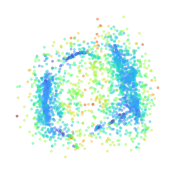

In [23]:
#########################################################################
############### Initial TSNE plot colored by gain       #################
#########################################################################

fig = plt.figure(figsize=(2,2))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
#ax1=fig.add_subplot(gs[1,0])
neuron = np.argsort(data_snr)[-89]



#x_proj = TSNE(n_components = 2,perplexity = 200).fit_transform(response_matrix.T)
fit = umap.UMAP(n_components = 2,densmap = True,dens_lambda=2,n_neighbors =response_matrix.shape[1]//4)
#fit = umap.UMAP(n_components = 2,n_neighbors =response_matrix.shape[1]//4)
#x_proj = PCA().fit_transform(response_matrix.T)
x_proj= fit.fit_transform(response_matrix.T)
# sns.scatterplot(x=x_proj[:,0], y=x_proj[:,1],s=4,ax=ax,legend = False,lw = 0,alpha = .45,color='gray')
# sns.scatterplot(x=x_proj[None,neuron,0], y=x_proj[None,neuron,1],s=14,ax=ax,legend = False,lw = 0,alpha = 1)

sns.scatterplot(x=x_proj[:,0], y=x_proj[:,1],s=4,ax=ax,legend = False,lw = 0,alpha = .5,hue = g,palette = 'turbo')


ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)

plt.savefig('Figures/Figure_1_b.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)


<Axes: ylabel='Count'>

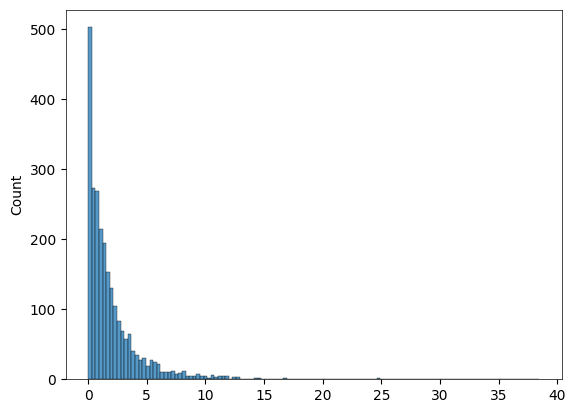

In [19]:
plt.figure()
sns.histplot(x = s)

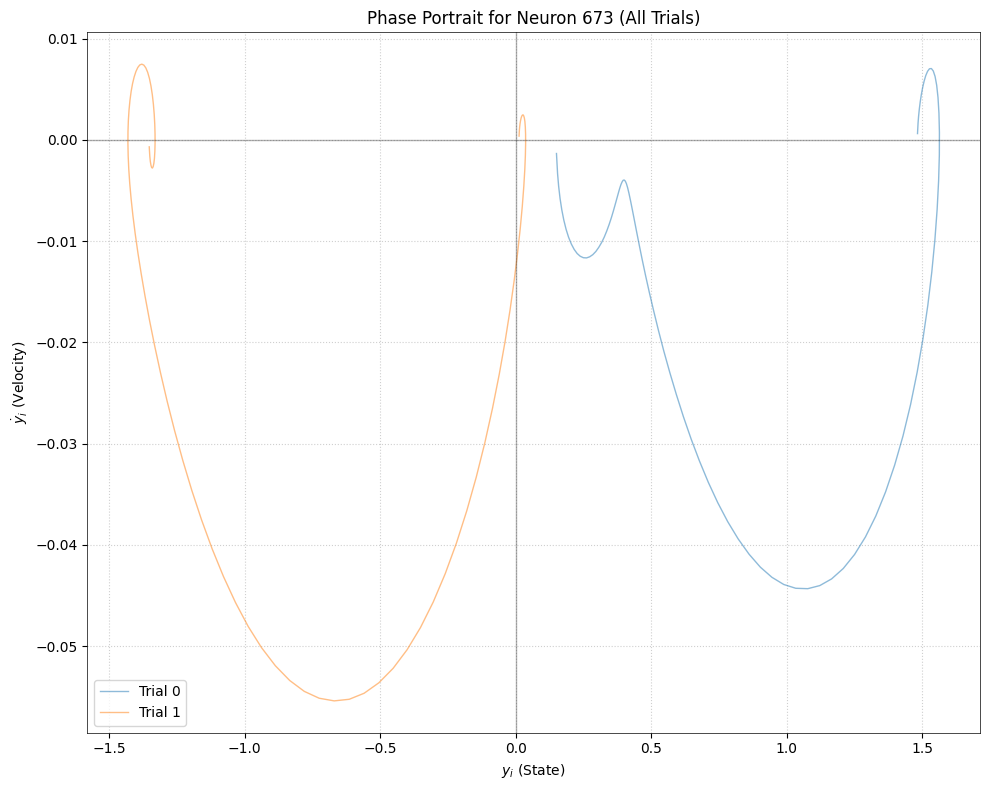

In [27]:
import torch
import matplotlib.pyplot as plt

def plot_phase_portraits(y, neuron_idx, dt=1.0, alpha=0.5):
    """
    Plots dot_yi vs yi for a specific neuron across all trials.

    Args:
        y: Tensor of shape (trials, time, neurons)
        neuron_idx: The integer index of the neuron to plot
        dt: Time step for derivative calculation
        alpha: Transparency for trial lines
    """
    # 1. Compute velocity (dot_y)
    dot_y = torch.gradient(y, spacing=dt, dim=1)[0]

    # 2. Extract the specific neuron's data across all trials
    # Shape: (trials, time)
    y_n = y[:, :, neuron_idx].cpu().numpy()
    dot_y_n = dot_y[:, :, neuron_idx].cpu().numpy()

    plt.figure(figsize=(10, 8))

    # 3. Plot each trial
    trials = y_n.shape[0]
    for t in range(trials):
        plt.plot(y_n[t], dot_y_n[t], alpha=alpha, linewidth=1, label=f'Trial {t}' if trials < 10 else None)

    # 4. Add the 'Linear Decay' reference line (dot_y = -y)
    # This represents the natural relaxation of the neuron
    all_y = y_n.flatten()
    y_range = [all_y.min(), all_y.max()]
    # plt.plot(y_range, [-y_range[0], -y_range[1]],
    #          color='black', linestyle='--', linewidth=2, label='Passive Decay ($\dot{y}=-y$)')

    # 5. Formatting
    plt.axhline(0, color='black', lw=1, alpha=0.3)
    plt.axvline(0, color='black', lw=1, alpha=0.3)
    plt.title(f"Phase Portrait for Neuron {neuron_idx} (All Trials)")
    plt.xlabel("$y_i$ (State)")
    plt.ylabel("$\dot{y}_i$ (Velocity)")
    plt.grid(True, linestyle=':', alpha=0.6)

    if trials < 10:
        plt.legend()

    plt.tight_layout()
    plt.show()

# Usage:
plot_phase_portraits(torch.FloatTensor(responses), neuron_idx=torch.argsort(g)[12], dt=1)

In [349]:
torch.argsort(g)

tensor([1131, 1204,  374,  ..., 1924, 1728, 1887])

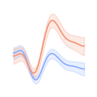

In [25]:
#############################################################
############### PSTH ########################################
#############################################################



############### ******** ############
response_matrix_train = (response_matrix_train - np.mean(response_matrix_train, axis=(0, 1, 2),
                                                         keepdims=True)) / np.std(response_matrix_train,
                                                                                  axis=(0, 1, 2),
                                                                                  keepdims=True)



#neuron = np.argsort( beta.detach()[:rnn.n])[0]
#neuron  = 2
#neuron = np.argsort(snr[:rnn.n])[-2]
#neuron = np.argsort(g)[-5]
rows = []
for condition in range(response_matrix_train.shape[1]):
    for trial in range(response_matrix_train.shape[0]):
        for t in range(response_matrix_train.shape[2]):
            rows.append({'condition': condition,
                         'trial': trial,
                         't':t,
                         'x': response_matrix_train[trial, condition, t, neuron].item(),})
df = pd.DataFrame(rows)
fig = plt.figure(figsize=(1,1))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
sns.lineplot(data = df[df.condition ==0], x='t', y='x',errorbar = 'sd',ax=ax,legend=False,lw=1,color=sns.color_palette("coolwarm",n_colors =3)[0])
sns.lineplot(data = df[df.condition ==1], x='t', y='x',errorbar = 'sd',ax=ax,legend=False,lw=1,color=sns.color_palette("coolwarm",n_colors =3)[2])

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.xaxis.set_tick_params(labelsize=6, bottom=True)
ax.yaxis.set_tick_params(labelsize=6, left=True)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
#ax.set_ylim(-4,4)
ax.set_ylabel("Rate (Z-scored)",size = 6)
ax.set_xlabel("Time from stim",size = 6)
plt.savefig('Figures/Figure_1_2.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)

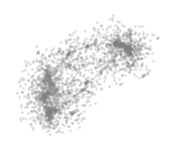

In [360]:
#########################################################################
############### Initial TSNE plot colored by gain       #################
#########################################################################

fig = plt.figure(figsize=(2,2))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
#ax1=fig.add_subplot(gs[1,0])




#x_proj = TSNE(n_components = 2,perplexity = 300).fit_transform(response_matrix.T)
#fit = umap.UMAP(n_components = 2,densmap = True,dens_lambda=1,n_neighbors =200,min_dist=.2)
#x_proj= fit.fit_transform(response_matrix.T)
sns.scatterplot(x=x_proj[:,0], y=x_proj[:,1],s=4,ax=ax,legend = False,lw = 0,alpha = .25,color='gray')
#sns.scatterplot(x=x_proj[:,0], y=x_proj[:,1],s=5,ax=ax,legend = False,lw = 0,alpha = .25,hue = data_snr,palette = 'turbo')


ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_aspect('equal')
plt.savefig('Figures/Figure_1_c.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)


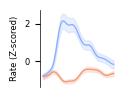

<Figure size 640x480 with 0 Axes>

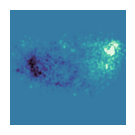

In [297]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.animation import FuncAnimation
from scipy.ndimage import gaussian_filter
from sklearn.manifold import Isomap
from sklearn.manifold import TSNE

#mean_responses = np.mean(response_matrix_train, axis=0)
# mean_responses = responses
# pca = TSNE(n_components = 2)
#
# x_proj = pca.fit_transform(responses.T)

embedding =(50*x_proj[:,:2]).astype(int) - (50*x_proj[:,:2]).astype(int).min()
def spatial_embedding(response,embedding,sigma):
    m = np.zeros((embedding.max()+1,embedding.max()+1))
    for neuron in range(embedding.shape[0]):
        m[embedding[neuron,1],embedding[neuron,0]] = response[neuron]
    m = np.flipud(m)
    return gaussian_filter(m,sigma)

t = 90
sigma = 10
vmin = -.02
vmax = .02
m = spatial_embedding(responses[0,t,:],embedding,sigma=sigma)
plt.figure()
from scipy.ndimage import gaussian_filter
fig = plt.figure(figsize=(1.5,1.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
sns.heatmap(m ,vmin =vmin,vmax = vmax,cbar = False,ax=ax,cmap='mako')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_aspect('equal')
plt.savefig('Figures/Figure_1_'+str(t)+'.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)


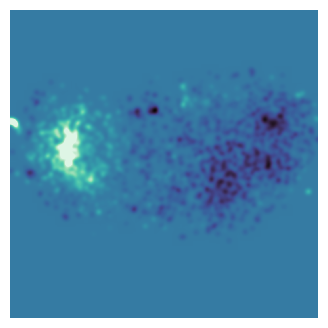

In [300]:
num_frames = responses.shape[1]
trial =0

data_list = [spatial_embedding(responses[trial,i,:],embedding,sigma)  for i in range(num_frames)]

# 2. Set up the figure and axes
fig, ax = plt.subplots(figsize=(4,4))

# Set consistent colorbar range (vmin/vmax) if desired, for smooth animation


def update(frame_num):
    """Updates the heatmap for each frame of the animation."""
    ax.clear()  # Clear the previous frame's axis
    current_data = data_list[frame_num]
    sns.heatmap(current_data, ax=ax, cbar=False, vmin=vmin, vmax=vmax,cmap = 'mako')
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.axes.get_xaxis().set_visible(False)
    ax.axes.get_yaxis().set_visible(False)
    ax.set_aspect('equal')
anim = FuncAnimation(fig, update, frames=num_frames, interval=200, blit=False)
try:
    os.makedirs("Movies/" + eid)
except:
    pass
anim.save('Movies/' + eid +'/' +'trial_'+str(trial) + ".mp4", writer='ffmpeg', fps=5)

In [291]:
eid

'746d1902-fa59-4cab-b0aa-013be36060d5'